# Étape 2 : exploration des données éCO2mix

Source : RTE, *Données éCO2mix nationales consolidées et définitives* (open data, Licence Ouverte v2.0 Etalab).
Le notebook se lance depuis `notebooks/` après `python -m src.data`. Toutes les valeurs affichées viennent de cette exécution.

In [1]:
import os
os.chdir("..")  # run from the project root so that data/ and src/ are found

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_raw, to_half_hourly, to_paris_time

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
raw = load_raw()
df = to_half_hourly(raw)
local = to_paris_time(df)          # local time, used only for calendar effects
cons = local["consommation"]       # MW, 30-minute step
print(f"{len(df)} half-hourly slots from {df.index[0]} to {df.index[-1]} (UTC)")
print("Missing slots (NaN):", int(df["consommation"].isna().sum()))

Matplotlib is building the font cache; this may take a moment.


257134 half-hourly slots from 2011-12-31 23:00:00+00:00 to 2026-08-31 21:30:00+00:00 (UTC)
Missing slots (NaN): 29


## 1. Contrôles de qualité

Le fichier brut contient une ligne **tous les 15 minutes**, mais `consommation` n'est renseignée qu'aux minutes :00 et :30 (les lignes :15 et :45 portent seulement des prévisions RTE). Le vrai pas de temps de la cible est donc de **30 minutes**.

In [2]:
print("Raw rows:", len(raw))
print("Duplicated timestamps in raw:", int(raw["date_heure"].duplicated().sum()))
print("consommation empty, by minute of the hour:")
print(raw.groupby(raw["date_heure"].dt.minute)["consommation"].apply(lambda s: int(s.isna().sum())).to_string())
print()
print("Status of the data (nature):")
print(df.dropna(subset=["nature"]).groupby("nature")["consommation"].agg(["count"]).assign(
    first=df.dropna(subset=["nature"]).groupby("nature").apply(lambda g: g.index.min()),
    last=df.dropna(subset=["nature"]).groupby("nature").apply(lambda g: g.index.max())).to_string())
print()
missing = df.index[df["consommation"].isna()]
print("Missing slots (UTC), by year-month:")
print(pd.Series(1, index=missing).groupby(missing.strftime("%Y-%m")).sum().to_string())
print("zero or negative values:", int((df["consommation"] <= 0).sum()))

Raw rows: 514272
Duplicated timestamps in raw: 60
consommation empty, by minute of the hour:
date_heure
0          1
15    128568
30         0
45    128568

Status of the data (nature):


                      count                     first                      last
nature                                                                         
Données consolidées   11661 2025-12-31 23:30:00+00:00 2026-08-31 21:30:00+00:00
Données définitives  245444 2011-12-31 23:00:00+00:00 2025-12-31 22:30:00+00:00

Missing slots (UTC), by year-month:
date_heure
2012-10    2
2013-10    2
2014-10    2
2015-10    2
2016-10    2
2017-10    2
2018-10    2
2019-10    2
2020-10    2
2021-10    2
2022-10    2
2023-10    2
2024-10    2
2025-10    2
2025-12    1
zero or negative values: 0


**Lecture.**
- Le fichier est en **UTC**, ce qui évite l'ambiguïté du changement d'heure dans l'index.
- **Printemps** (heure d'été) : 4 horodatages dupliqués par an, parfois avec des valeurs différentes. Choix : moyenne des deux lignes.
- **Automne** (heure d'hiver) : **une heure manque** chaque année (00:00 et 00:30 UTC), soit 2 créneaux par an. On ne les remplit pas.
- Un créneau manque aussi à la jonction entre données définitives et consolidées (31 décembre 2025, 23:00 UTC).
- Les causes exactes de ces anomalies (comment RTE exporte l'heure locale) ne sont **pas documentées dans la fiche** : on constate, on ne l'explique pas.

## 2. Une semaine type (hiver)

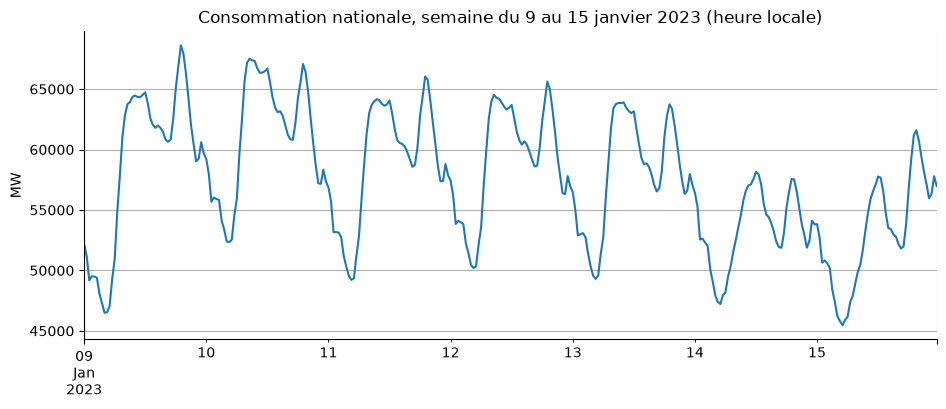

In [3]:
week = cons["2023-01-09":"2023-01-15"]
fig, ax = plt.subplots()
week.plot(ax=ax)
ax.set_title("Consommation nationale, semaine du 9 au 15 janvier 2023 (heure locale)")
ax.set_ylabel("MW"); ax.set_xlabel("")
plt.show()

## 3. Une année et toutes les années

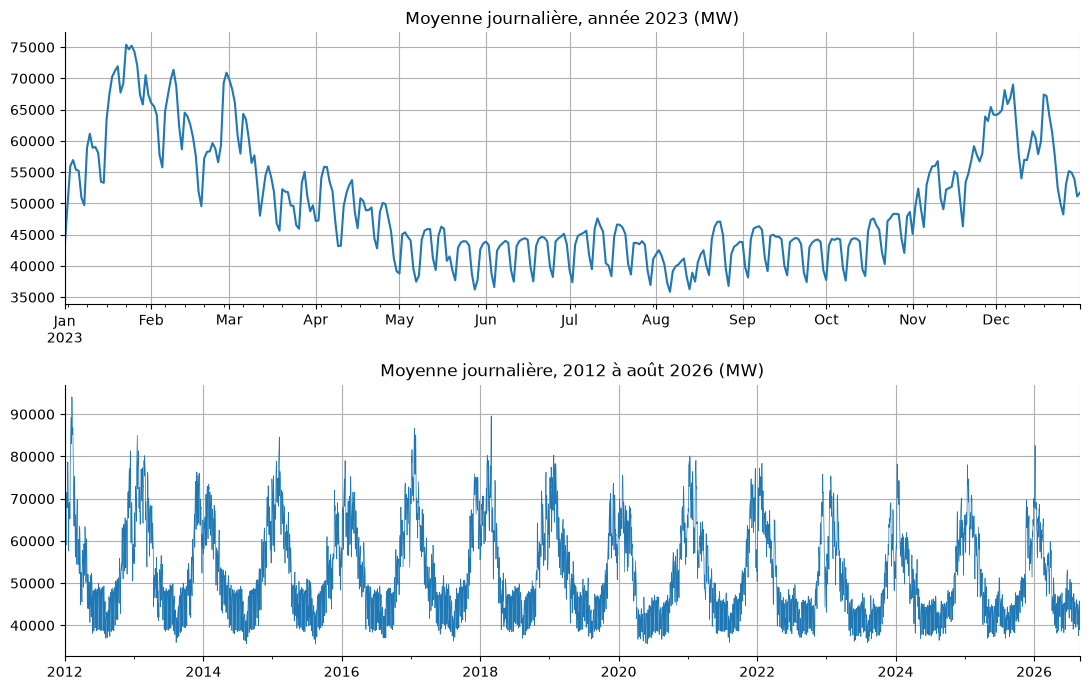

               mean  count
date_heure                
2012        55398.0  17566
2013        56185.0  17518
2014        52780.0  17518
2015        54013.0  17518
2016        54682.0  17566
2017        54686.0  17518
2018        54283.0  17518
2019        53708.0  17518
2020        50841.0  17566
2021        53493.0  17518
2022        51388.0  17518
2023        49723.0  17518
2024        50101.0  17566
2025        50671.0  17518
2026        50667.0  11661


In [4]:
daily = cons.resample("D").mean()
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
daily["2023"].plot(ax=axes[0]); axes[0].set_title("Moyenne journalière, année 2023 (MW)"); axes[0].set_xlabel("")
daily.plot(ax=axes[1], lw=0.5); axes[1].set_title("Moyenne journalière, 2012 à août 2026 (MW)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

yearly = cons.groupby(cons.index.year).agg(["mean", "count"]).round(0)
print(yearly.to_string())

## 4. Profil par heure et par jour de la semaine

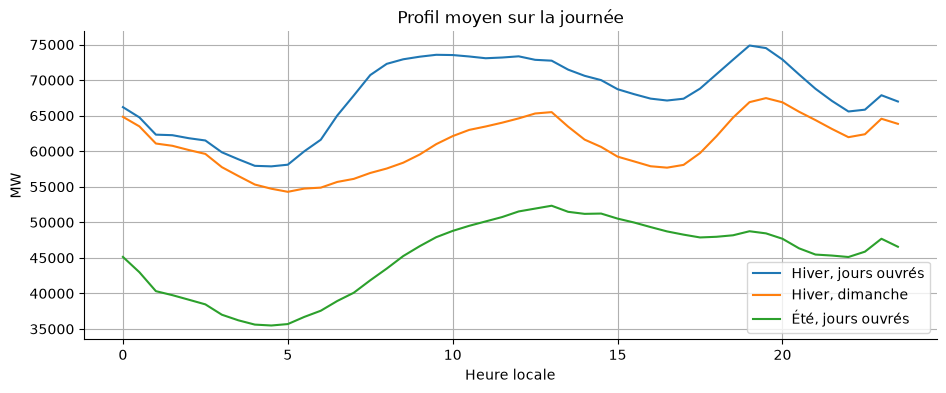

Winter weekdays, local maxima (hour -> MW):
hour
9.5     73566.0
12.0    73352.0
19.0    74875.0
Minimum: 4.5 h -> 57872 MW
Summer weekdays, local maxima:
hour
13.0    52334.0
19.0    48744.0


In [5]:
cons_df = cons.to_frame("mw")
cons_df["hour"] = cons_df.index.hour + cons_df.index.minute / 60
cons_df["dow"] = cons_df.index.day_of_week   # 0 = Monday
cons_df["month"] = cons_df.index.month

winter_wd = cons_df[cons_df["month"].isin([12, 1, 2]) & (cons_df["dow"] < 5)]
summer_wd = cons_df[cons_df["month"].isin([7, 8]) & (cons_df["dow"] < 5)]
winter_sun = cons_df[cons_df["month"].isin([12, 1, 2]) & (cons_df["dow"] == 6)]

fig, ax = plt.subplots()
for name, sub in [("Hiver, jours ouvrés", winter_wd), ("Hiver, dimanche", winter_sun), ("Été, jours ouvrés", summer_wd)]:
    sub.groupby("hour")["mw"].mean().plot(ax=ax, label=name)
ax.set_xlabel("Heure locale"); ax.set_ylabel("MW"); ax.legend(); ax.set_title("Profil moyen sur la journée")
plt.show()

def local_maxima(s: pd.Series) -> pd.Series:
    """Return the points higher than their two neighbours on each side."""
    return s[(s > s.shift(1)) & (s > s.shift(-1)) & (s > s.shift(2)) & (s > s.shift(-2))]

prof = winter_wd.groupby("hour")["mw"].mean()
print("Winter weekdays, local maxima (hour -> MW):")
print(local_maxima(prof).round(0).to_string())
print("Minimum:", prof.idxmin(), "h ->", round(prof.min()), "MW")
print("Summer weekdays, local maxima:")
print(local_maxima(summer_wd.groupby("hour")["mw"].mean()).round(0).to_string())

In [6]:
print("Mean consumption by day of week (0 = Monday), MW:")
print(cons_df.groupby("dow")["mw"].mean().round(0).to_string())
print()
print("Mean consumption by month, MW:")
print(cons_df.groupby("month")["mw"].mean().round(0).to_string())

Mean consumption by day of week (0 = Monday), MW:
dow
0    53632.0
1    54986.0
2    55118.0
3    54963.0
4    54386.0
5    49673.0
6    47478.0

Mean consumption by month, MW:
month
1     68412.0
2     66066.0
3     58255.0
4     50334.0
5     45109.0
6     44643.0
7     45085.0
8     42200.0
9     44892.0
10    48651.0
11    58095.0
12    63953.0


## 5. Jours fériés : l'hypothèse « plus bas qu'un jour ouvré normal »

On compare les jours fériés à date fixe tombant en semaine à la moyenne journalière du même jour de la semaine, une semaine avant et une semaine après. C'est un contrôle simple, pas un modèle : les ponts et les vacances brouillent un peu le résultat.

In [7]:
hol = [(1, 5), (8, 5), (14, 7), (15, 8), (1, 11), (11, 11), (25, 12)]   # (day, month)
rows = []
for year in range(2012, 2026):
    for day, month in hol:
        t = pd.Timestamp(year, month, day, tz="Europe/Paris")
        if t.day_of_week < 5:
            neigh = [daily.get(t - pd.Timedelta(days=7)), daily.get(t + pd.Timedelta(days=7))]
            neigh = [x for x in neigh if pd.notna(x)]
            rows.append((year, day, month, daily.get(t) / np.mean(neigh)))
ratio = pd.DataFrame(rows, columns=["year", "day", "month", "ratio"])
print(f"{len(ratio)} public holidays on a weekday")
print("holiday / same weekday +-1 week: mean", round(ratio["ratio"].mean(), 3),
      "| min", round(ratio["ratio"].min(), 3), "| max", round(ratio["ratio"].max(), 3))
sun = daily[daily.index.day_of_week == 6].mean(); wk = daily[daily.index.day_of_week < 5].mean()
print("Sunday / weekday (daily means):", round(sun / wk, 3))

73 public holidays on a weekday
holiday / same weekday +-1 week: mean 0.885 | min 0.721 | max 1.045
Sunday / weekday (daily means): 0.869


## 6. COVID

{'2019': 52977, '2020': 44187}
variation 2020 vs 2019 (16 mars - 10 mai): -16.6%


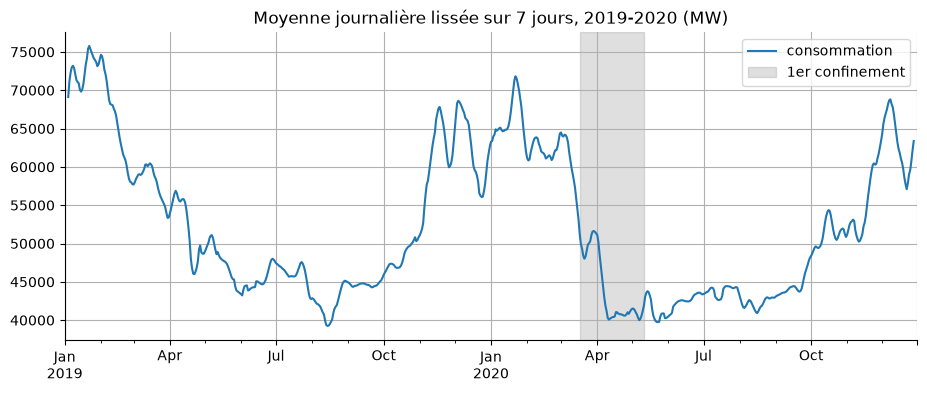

In [8]:
spring = {"2019": daily["2019-03-16":"2019-05-10"].mean(), "2020": daily["2020-03-16":"2020-05-10"].mean()}
print({k: round(v) for k, v in spring.items()})
print("variation 2020 vs 2019 (16 mars - 10 mai):", f"{spring['2020'] / spring['2019'] - 1:.1%}")
fig, ax = plt.subplots()
daily["2019-01-01":"2020-12-31"].rolling(7, center=True).mean().plot(ax=ax)
ax.axvspan("2020-03-17", "2020-05-11", color="grey", alpha=0.25, label="1er confinement")
ax.set_title("Moyenne journalière lissée sur 7 jours, 2019-2020 (MW)"); ax.set_xlabel(""); ax.legend()
plt.show()

## 7. Mémoire de la série et référence RTE

In [9]:
s = df["consommation"]
print("Autocorrelation, lag 1 day (48 steps): ", round(s.autocorr(48), 3))
print("Autocorrelation, lag 1 week (336 steps):", round(s.autocorr(336), 3))

ok = df.dropna(subset=["consommation", "prevision_j1"])
err = ok["prevision_j1"] - ok["consommation"]
print(f"RTE's own J-1 forecast, all years: MAE = {err.abs().mean():.0f} MW, MAPE = {(err.abs() / ok['consommation']).mean():.2%}")
print("(Benchmark only: not a variable of our models.)")

Autocorrelation, lag 1 day (48 steps):  0.933
Autocorrelation, lag 1 week (336 steps): 0.904
RTE's own J-1 forecast, all years: MAE = 950 MW, MAPE = 1.82%
(Benchmark only: not a variable of our models.)


## Ce qu'on retient

À compléter dans `docs/etapes/ETAPE_02.md` à partir des sorties ci-dessus.